In [1]:
# 1. Dependencies
import json
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

# 2. Paths & Variables
train_dir = Path("../data/raw/train/train_images")
json_path = Path("../data/raw/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json")
target_size = (512, 512)
batch_size = 4
epochs = 15
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 3. Data Parsing & Split
with open(json_path, "r") as f:
    coco = json.load(f)

image_dict = {img["id"]: img["file_name"] for img in coco["images"]}
image_ids = list(image_dict.keys())

ann_dict = {img_id: [] for img_id in image_ids}
for ann in coco["annotations"]:
    if ann["image_id"] in ann_dict:
        ann_dict[ann["image_id"]].append(ann)


/home/virendra2605/Documents/inter-iit-cvps/task-a-solar-fragments/.venv/lib64/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [17]:

# 5. Stratify by filament count
counts = [len(ann_dict[i]) for i in image_ids]
bins = np.digitize(counts, bins=[3, 7, 12, 18]) 
train_ids, val_ids = train_test_split(image_ids, test_size=0.2, stratify=bins, random_state=42)
print(f"Training images: {len(train_ids)} | Validation images: {len(val_ids)}")

class FilamentDataset(Dataset):
    def __init__(self, image_ids, img_dir, img_dict, ann_dict, size):
        self.image_ids = image_ids
        self.img_dir = img_dir
        self.img_dict = img_dict
        self.ann_dict = ann_dict
        self.size = size
        
    def __len__(self):
        return len(self.image_ids)
        
    def __getitem__(self, idx):
        img_id = self.image_ids[idx]
        img_path = str(self.img_dir / self.img_dict[img_id])
        
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask = np.zeros_like(image, dtype=np.uint8)
        
        # ponytail: Calculate centroids on the fly.
        # Upgrade path: Precompute these in the JSON parsing step if CPU becomes a bottleneck.
        centers = []
        for ann in self.ann_dict[img_id]:
            for poly in ann.get("segmentation", []):
                poly_pts = np.array(poly, dtype=np.float32).reshape(-1, 2)
                poly_pts = np.round(poly_pts).astype(np.int32)
                cv2.fillPoly(mask, [poly_pts], 1)
                centers.append(poly_pts.mean(axis=0)) 
                
        h, w = image.shape
        th, tw = self.size
        
        # Biased Cropping: 50% chance to center on a filament to ensure foreground exposure.
        if len(centers) > 0 and torch.rand(1).item() > 0.5:
            cx, cy = centers[torch.randint(len(centers), (1,)).item()]
            cx, cy = int(cx), int(cy)
            # Clip bounds to keep the crop inside the image
            i = np.clip(cy - th // 2, 0, h - th)
            j = np.clip(cx - tw // 2, 0, w - tw)
        else:
            # Standard random crop for the other 50% (teaches the model to recognize empty space)
            i = torch.randint(0, h - th + 1, size=(1,)).item()
            j = torch.randint(0, w - tw + 1, size=(1,)).item()
            
        image = image[i:i+th, j:j+tw]
        mask = mask[i:i+th, j:j+tw]
        
        image = torch.from_numpy(image).float().unsqueeze(0) / 255.0
        mask = torch.from_numpy(mask).float().unsqueeze(0)
        
        return image, mask

train_loader = DataLoader(FilamentDataset(train_ids, train_dir, image_dict, ann_dict, target_size), 
                          batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(FilamentDataset(val_ids, train_dir, image_dict, ann_dict, target_size), 
                        batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)



Training images: 923 | Validation images: 231


In [18]:






# 6. Loss & Metrics
class FocalDiceLoss(nn.Module):
    def __init__(self, alpha=0.66, gamma=2.0, focal_weight=0.5):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.focal_weight = focal_weight
        
    def forward(self, logits, targets, smooth=1.0):
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1 - probs) * (1 - targets)
        focal_loss = (self.alpha * (1 - p_t) ** self.gamma * bce).mean()
        
        intersection = (probs * targets).sum(dim=(2,3))
        union = probs.sum(dim=(2,3)) + targets.sum(dim=(2,3))
        dice_loss = 1.0 - (2. * intersection + smooth) / (union + smooth)
        
        return self.focal_weight * focal_loss + (1 - self.focal_weight) * dice_loss.mean()

def calculate_iou(logits, targets, threshold=0.5, eps=1e-6):
    preds = (torch.sigmoid(logits) > threshold).float()
    intersection = (preds * targets).sum(dim=(2,3))
    union = (preds + targets).sum(dim=(2,3)) - intersection
    return ((intersection + eps) / (union + eps)).mean().item()



In [4]:
class LeanUNet(nn.Module):
    def __init__(self):
        super().__init__()
        
        # MORDEN upgrade: 5x5 kernels + InstanceNorm + LeakyReLU
        def conv_block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, kernel_size=5, padding=2), 
                nn.InstanceNorm2d(out_c), 
                nn.LeakyReLU(0.01, inplace=True),
                
                nn.Conv2d(out_c, out_c, kernel_size=5, padding=2), 
                nn.InstanceNorm2d(out_c), 
                nn.LeakyReLU(0.01, inplace=True)
            )
        
        self.enc1 = conv_block(1, 16)
        self.enc2 = conv_block(16, 32)
        self.enc3 = conv_block(32, 64)
        
        self.pool = nn.MaxPool2d(2, 2)
        
        self.bot = conv_block(64, 128)
        
        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec3 = conv_block(128, 64) 
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = conv_block(64, 32)
        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = conv_block(32, 16)
        
        self.out = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        
        b = self.bot(self.pool(e3))
        
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        
        return self.out(d1)

In [19]:
class FocalDiceLoss(nn.Module):
    def __init__(self, alpha=0.66, gamma=2.0, focal_weight=0.5):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.focal_weight = focal_weight
        
    def forward(self, logits, targets, smooth=1.0):
        # Focal Loss (per MORDEN hyperparameters)
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1 - probs) * (1 - targets)
        focal_loss = self.alpha * (1 - p_t) ** self.gamma * bce
        focal_loss = focal_loss.mean()
        
        # Dice Loss
        intersection = (probs * targets).sum(dim=(2,3))
        union = probs.sum(dim=(2,3)) + targets.sum(dim=(2,3))
        dice_loss = 1.0 - (2. * intersection + smooth) / (union + smooth)
        
        return self.focal_weight * focal_loss + (1 - self.focal_weight) * dice_loss.mean()

In [ ]:
# 7. Training Loop
model = LeanUNet().to(device)
criterion = FocalDiceLoss().to(device)
optimizer = AdamW(model.parameters(), lr=1e-3)

print(f"Starting MORDEN-lite Training on {device}...  config: {epochs} epochs, batch size: {batch_size}, target size: {target_size}, comment = changes dataset scheme to include more foreground samples and reduce batch size to 4 for better convergence.")

for epoch in range(epochs):
    model.train()
    train_loss, train_iou = 0.0, 0.0
    
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]")
    for images, masks in pbar:
        images, masks = images.to(device), masks.to(device)
        
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        train_iou += calculate_iou(logits, masks)
        pbar.set_postfix(loss=f"{loss.item():.4f}")
        
    model.eval()
    val_loss, val_iou = 0.0, 0.0
    with torch.no_grad():
        for images, masks in tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Val]"):
            images, masks = images.to(device), masks.to(device)
            logits = model(images)
            val_loss += criterion(logits, masks).item()
            val_iou += calculate_iou(logits, masks)
            
    print(f"Epoch {epoch+1} | Train Loss: {train_loss/len(train_loader):.4f} | Val Loss: {val_loss/len(val_loader):.4f} | Val IoU: {val_iou/len(val_loader):.4f}")

Starting MORDEN-lite Training on cuda...


Epoch 1/15 [Val]: 100%|██████████| 58/58 [00:03<00:00, 14.83it/s]


Epoch 1 | Train Loss: 0.4922 | Val Loss: 0.4723 | Val IoU: 0.2919


Epoch 2/15 [Val]: 100%|██████████| 58/58 [00:03<00:00, 14.88it/s]


Epoch 2 | Train Loss: 0.4451 | Val Loss: 0.4068 | Val IoU: 0.2962


...

Epoch 13 | Train Loss: 0.2700 | Val Loss: 0.2773 | Val IoU: 0.4457


Epoch 14/15 [Val]: 100%|██████████| 58/58 [00:04<00:00, 13.70it/s]


Epoch 14 | Train Loss: 0.2792 | Val Loss: 0.2644 | Val IoU: 0.4668


Epoch 15/15 [Val]: 100%|██████████| 58/58 [00:04<00:00, 13.68it/s]

Epoch 15 | Train Loss: 0.2629 | Val Loss: 0.2624 | Val IoU: 0.5157


Full-Disk Metrics -> IoU: 0.5802 | Precision: 0.6623 | Recall: 0.8239


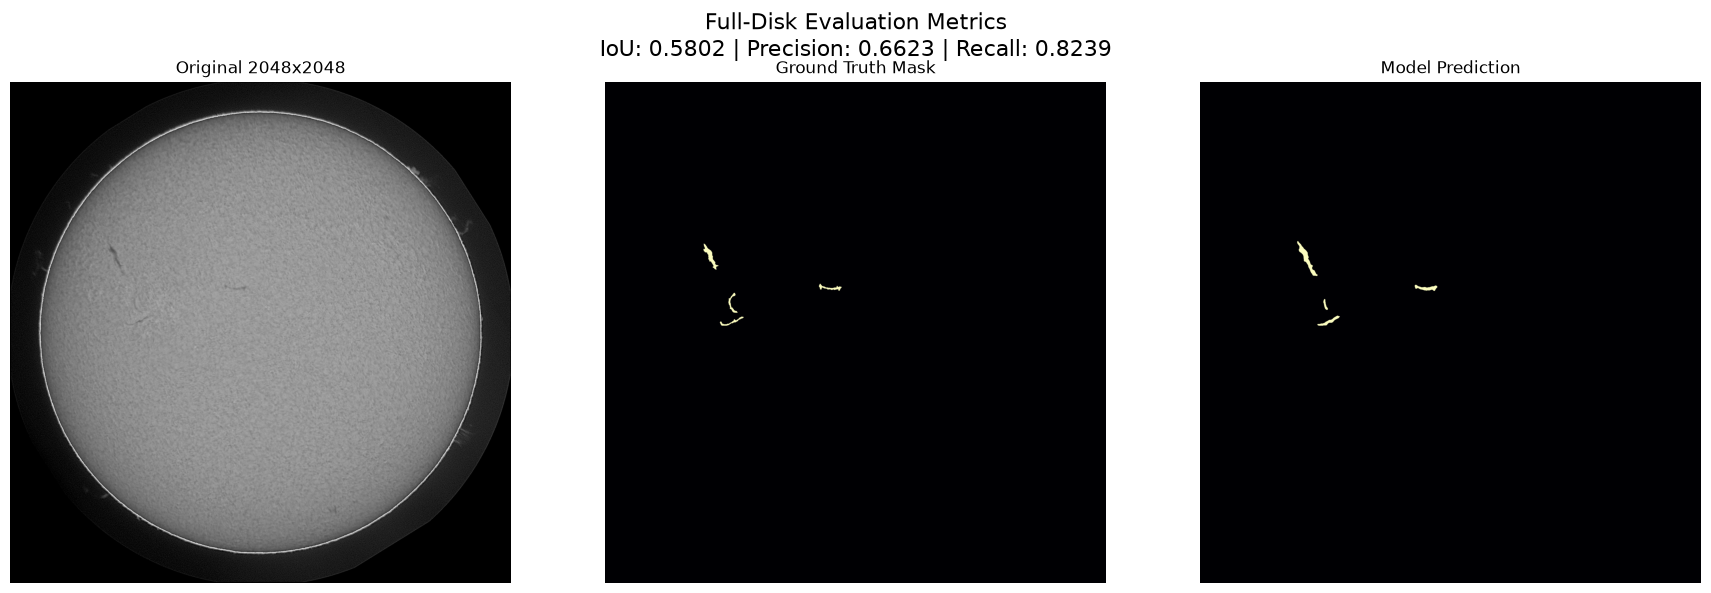

In [15]:
# 1. Full-Disk Dataset for Evaluation
class FullDiskDataset(Dataset):
    def __init__(self, image_ids, img_dir, img_dict, ann_dict):
        self.image_ids = image_ids
        self.img_dir = img_dir
        self.img_dict = img_dict
        self.ann_dict = ann_dict
        
    def __len__(self): return len(self.image_ids)
        
    def __getitem__(self, idx):
        img_id = self.image_ids[idx]
        img_path = str(self.img_dir / self.img_dict[img_id])
        
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask = np.zeros_like(image, dtype=np.uint8)
        
        for ann in self.ann_dict[img_id]:
            for poly in ann.get("segmentation", []):
                poly_pts = np.round(np.array(poly, dtype=np.float32).reshape(-1, 2)).astype(np.int32)
                cv2.fillPoly(mask, [poly_pts], 1)
                
        image = torch.from_numpy(image).float().unsqueeze(0) / 255.0
        mask = torch.from_numpy(mask).float().unsqueeze(0)
        return image, mask

# 2. Run Inference on a single 2048x2048 image
full_val_dataset = FullDiskDataset(val_ids, train_dir, image_dict, ann_dict)
img_tensor, mask_tensor = full_val_dataset[0]

model.eval()
with torch.no_grad():
    # Add batch dimension and move to GPU
    logits = model(img_tensor.unsqueeze(0).to(device))
    preds = (torch.sigmoid(logits) > 0.5).squeeze().cpu().numpy()

mask_np = mask_tensor.squeeze().numpy()
img_np = img_tensor.squeeze().numpy()

# 3. Calculate PS-Required Metrics (IoU, Precision, Recall)
intersection = np.logical_and(preds, mask_np).sum()
union = np.logical_or(preds, mask_np).sum()
true_positives = intersection
false_positives = (preds > mask_np).sum()
false_negatives = (mask_np > preds).sum()

iou = intersection / (union + 1e-6)
precision = true_positives / (true_positives + false_positives + 1e-6)
recall = true_positives / (true_positives + false_negatives + 1e-6)

print(f"Full-Disk Metrics -> IoU: {iou:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f}")

# 4. Visualize
plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.imshow(img_np, cmap='gray')
plt.title("Original 2048x2048")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask_np, cmap='magma')
plt.title("Ground Truth Mask")
plt.axis('off')


plt.subplot(1, 3, 3)
plt.imshow(preds, cmap='magma')
plt.title("Model Prediction")
plt.axis('off')

plt.suptitle(f"Full-Disk Evaluation Metrics\nIoU: {iou:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f}", fontsize=16)

plt.tight_layout()
plt.show()

In [11]:
def remove_small_objects(binary_mask, min_size=64):
    """ponytail: OpenCV connected components is exponentially faster than DenseCRF or DBSCAN."""
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary_mask.astype(np.uint8), connectivity=8)
    clean_mask = np.zeros_like(binary_mask)
    for i in range(1, num_labels): # Skip 0 (background)
        if stats[i, cv2.CC_STAT_AREA] >= min_size:
            clean_mask[labels == i] = 1
    return clean_mask

print("Evaluating full validation set (2048x2048)...")

model.eval()
val_iou, val_precision, val_recall = 0.0, 0.0, 0.0

with torch.no_grad():
    pbar = tqdm(full_val_dataset, desc="Full-Disk Eval")
    for img_tensor, mask_tensor in pbar:
        # Add batch dim
        img_tensor = img_tensor.unsqueeze(0).to(device)
        mask_np = mask_tensor.squeeze().numpy()
        
        logits = model(img_tensor)
        preds = (torch.sigmoid(logits) > 0.5).squeeze().cpu().numpy()
        
        # Apply lazy post-processing
        preds_clean = remove_small_objects(preds, min_size=64)
        
        intersection = np.logical_and(preds_clean, mask_np).sum()
        union = np.logical_or(preds_clean, mask_np).sum()
        
        tp = intersection
        fp = (preds_clean > mask_np).sum()
        fn = (mask_np > preds_clean).sum()
        
        val_iou += intersection / (union + 1e-6)
        val_precision += tp / (tp + fp + 1e-6)
        val_recall += tp / (tp + fn + 1e-6)

n_val = len(full_val_dataset)
print(f"Final Baseline Metrics:")
print(f"Mean IoU:       {val_iou / n_val:.4f}")
print(f"Mean Precision: {val_precision / n_val:.4f}")
print(f"Mean Recall:    {val_recall / n_val:.4f}")

Evaluating full validation set (2048x2048)...


NameError: name 'full_val_dataset' is not defined

In [20]:
class TverskyLoss(nn.Module):
    def __init__(self, alpha=0.3, beta=0.7, smooth=1.0):
        super().__init__()
        self.alpha = alpha  # Weight for false negatives
        self.beta = beta    # Weight for false positives (higher beta = higher precision)
        self.smooth = smooth
        
    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        
        # Flatten label and prediction tensors
        probs = probs.view(-1)
        targets = targets.view(-1)
        
        true_pos = (probs * targets).sum()
        false_neg = ((1 - probs) * targets).sum()
        false_pos = (probs * (1 - targets)).sum()
        
        tversky = (true_pos + self.smooth) / (true_pos + self.alpha * false_neg + self.beta * false_pos + self.smooth)
        return 1.0 - tversky

In [21]:
import torchvision.models as models

# 1. The ResNet34 U-Net
class ResNetUNet(nn.Module):
    def __init__(self):
        super().__init__()
        # Load Pre-trained ResNet34 (standard torchvision dependency, no extra installs)
        resnet = models.resnet34(weights=models.ResNet34_Weights.DEFAULT)
        
        # ponytail: Collapse 3-channel RGB weights into 1 channel for H-alpha grayscale.
        self.firstconv = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.firstconv.weight.data = resnet.conv1.weight.data.sum(dim=1, keepdim=True)
        
        self.firstbn = resnet.bn1
        self.firstrelu = resnet.relu
        self.firstmaxpool = resnet.maxpool
        
        # Encoder Blocks (Pre-trained)
        self.encoder1 = resnet.layer1 # 64 channels
        self.encoder2 = resnet.layer2 # 128 channels
        self.encoder3 = resnet.layer3 # 256 channels
        self.encoder4 = resnet.layer4 # 512 channels
        
        # Decoder Blocks (Retaining our InstanceNorm + LeakyReLU upgrades)
        def dec_block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, padding=1), nn.InstanceNorm2d(out_c), nn.LeakyReLU(0.01, inplace=True),
                nn.Conv2d(out_c, out_c, 3, padding=1), nn.InstanceNorm2d(out_c), nn.LeakyReLU(0.01, inplace=True)
            )
            
        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = dec_block(512, 256) 
        
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = dec_block(256, 128) 
        
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = dec_block(128, 64)  
        
        self.up1 = nn.ConvTranspose2d(64, 64, 2, stride=2)
        self.dec1 = dec_block(128, 64)  
        
        self.final_up = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.final_dec = dec_block(32, 16)
        
        self.out = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        # Encode
        e0 = self.firstrelu(self.firstbn(self.firstconv(x)))
        e1 = self.encoder1(self.firstmaxpool(e0))
        e2 = self.encoder2(e1)
        e3 = self.encoder3(e2)
        b = self.encoder4(e3)
        
        # Decode (with skip connections)
        d4 = self.dec4(torch.cat([self.up4(b), e3], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e2], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e1], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e0], 1))
        
        return self.out(self.final_dec(self.final_up(d1)))

# 2. Re-instantiate the graph
model = ResNetUNet().to(device)
criterion = TverskyLoss().to(device)
optimizer = AdamW(model.parameters(), lr=1e-3)




In [20]:

# 3. Kick off the run
best_iou = 0.0
patience = 5
patience_counter = 0
best_model_path = "best_resnet_unet.pt"

print(f"Starting Transfer Learning Training on {device}...")

for epoch in range(epochs):
    model.train()
    train_loss, train_iou = 0.0, 0.0
    
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]")
    for images, masks in pbar:
        images, masks = images.to(device), masks.to(device)
        
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        train_iou += calculate_iou(logits, masks)
        pbar.set_postfix(loss=f"{loss.item():.4f}")
        
    model.eval()
    val_loss, val_iou = 0.0, 0.0
    with torch.no_grad():
        for images, masks in tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Val]"):
            images, masks = images.to(device), masks.to(device)
            logits = model(images)
            val_loss += criterion(logits, masks).item()
            val_iou += calculate_iou(logits, masks)
            
    val_iou_mean = val_iou / len(val_loader)
    print(f"Epoch {epoch+1} | Train Loss: {train_loss/len(train_loader):.4f} | Val Loss: {val_loss/len(val_loader):.4f} | Val Crop IoU: {val_iou_mean:.4f}")
    
    # ponytail: Saving to disk is safer than keeping copy.deepcopy() state_dicts in RAM.
    if val_iou_mean > best_iou:
        best_iou = val_iou_mean
        torch.save(model.state_dict(), best_model_path)
        patience_counter = 0
        print(f"  -> New best IoU! Saved to {best_model_path}")
    else:
        patience_counter += 1
        print(f"  -> No improvement. Patience: {patience_counter}/{patience}")
        if patience_counter >= patience:
            print("Early stopping triggered.")
            break

# 4. Load the best weights before moving to full-disk inference
model.load_state_dict(torch.load(best_model_path))
print("Best weights loaded into model.")

Starting Transfer Learning Training on cuda...


Epoch 1/15 [Val]: 100%|██████████| 58/58 [00:03<00:00, 15.20it/s]


Epoch 1 | Train Loss: 0.9610 | Val Loss: 0.9497 | Val Crop IoU: 0.1187
  -> New best IoU! Saved to best_resnet_unet.pt


Epoch 2/15 [Val]: 100%|██████████| 58/58 [00:03<00:00, 15.21it/s]


Epoch 2 | Train Loss: 0.9079 | Val Loss: 0.8640 | Val Crop IoU: 0.2185
  -> New best IoU! Saved to best_resnet_unet.pt


...

Epoch 13 | Train Loss: 0.3507 | Val Loss: 0.3605 | Val Crop IoU: 0.4810
  -> No improvement. Patience: 2/5


Epoch 14/15 [Val]: 100%|██████████| 58/58 [00:03<00:00, 15.18it/s]


Epoch 14 | Train Loss: 0.3574 | Val Loss: 0.5769 | Val Crop IoU: 0.3338
  -> No improvement. Patience: 3/5


Epoch 15/15 [Val]: 100%|██████████| 58/58 [00:03<00:00, 15.19it/s]


Epoch 15 | Train Loss: 0.3408 | Val Loss: 0.3522 | Val Crop IoU: 0.4952
  -> No improvement. Patience: 4/5
Best weights loaded into model.


In [22]:
# 1. Balanced Tversky Loss (trading a tiny bit of precision for a recall bump)
class TverskyLoss(nn.Module):
    def __init__(self, alpha=0.4, beta=0.6, smooth=1.0):
        super().__init__()
        self.alpha = alpha  # Weight for false negatives
        self.beta = beta    # Weight for false positives
        self.smooth = smooth
        
    def forward(self, logits, targets):
        probs = torch.sigmoid(logits).view(-1)
        targets = targets.view(-1)
        
        true_pos = (probs * targets).sum()
        false_neg = ((1 - probs) * targets).sum()
        false_pos = (probs * (1 - targets)).sum()
        
        tversky = (true_pos + self.smooth) / (true_pos + self.alpha * false_neg + self.beta * false_pos + self.smooth)
        return 1.0 - tversky

# 2. Load best previous weights and set up lower learning rate for fine-tuning
best_model_path = "best_resnet_unet.pt"
finetune_model_path = "best_resnet_unet_final.pt"

model.load_state_dict(torch.load(best_model_path))
criterion = TverskyLoss(alpha=0.4, beta=0.6).to(device)
optimizer = AdamW(model.parameters(), lr=1e-4) # Lower LR so we don't destroy pre-trained features

epochs_finetune = 5
best_iou = 0.4179 # Baseline from previous run

print("Starting Tversky Fine-Tuning...")

for epoch in range(epochs_finetune):
    model.train()
    train_loss = 0.0
    
    pbar = tqdm(train_loader, desc=f"Fine-Tune Epoch {epoch+1}/{epochs_finetune} [Train]")
    for images, masks in pbar:
        images, masks = images.to(device), masks.to(device)
        
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        pbar.set_postfix(loss=f"{loss.item():.4f}")
        
    model.eval()
    val_iou = 0.0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            logits = model(images)
            val_iou += calculate_iou(logits, masks)
            
    val_iou_mean = val_iou / len(val_loader)
    print(f"Epoch {epoch+1} | Val Crop IoU: {val_iou_mean:.4f}")
    
    if val_iou_mean > best_iou:
        best_iou = val_iou_mean
        torch.save(model.state_dict(), finetune_model_path)
        print(f"  -> New best IoU! Saved to {finetune_model_path}")

# Load the ultimate best weights
model.load_state_dict(torch.load(finetune_model_path if Path(finetune_model_path).exists() else best_model_path))
print("Final best weights loaded successfully.")

Starting Tversky Fine-Tuning...


Fine-Tune Epoch 1/5 [Train]: 100%|██████████| 231/231 [00:49<00:00,  4.67it/s, loss=0.1443]


Epoch 1 | Val Crop IoU: 0.4991
  -> New best IoU! Saved to best_resnet_unet_final.pt


Fine-Tune Epoch 2/5 [Train]: 100%|██████████| 231/231 [00:49<00:00,  4.65it/s, loss=0.4144]


Epoch 2 | Val Crop IoU: 0.4989


...

Epoch 3 | Val Crop IoU: 0.5642
  -> New best IoU! Saved to best_resnet_unet_final.pt


Fine-Tune Epoch 4/5 [Train]: 100%|██████████| 231/231 [00:49<00:00,  4.65it/s, loss=0.3186]


Epoch 4 | Val Crop IoU: 0.5287


Fine-Tune Epoch 5/5 [Train]: 100%|██████████| 231/231 [00:49<00:00,  4.64it/s, loss=0.3834]


Epoch 5 | Val Crop IoU: 0.5335
Final best weights loaded successfully.


In [24]:
def remove_small_objects(binary_mask, min_size=64):
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary_mask.astype(np.uint8), connectivity=8)
    clean_mask = np.zeros_like(binary_mask)
    for i in range(1, num_labels):
        if stats[i, cv2.CC_STAT_AREA] >= min_size:
            clean_mask[labels == i] = 1
    return clean_mask

print("Evaluating full validation set (2048x2048) with final weights...")

model.eval()
val_iou, val_precision, val_recall = 0.0, 0.0, 0.0

with torch.no_grad():
    pbar = tqdm(full_val_dataset, desc="Full-Disk Eval")
    for img_tensor, mask_tensor in pbar:
        img_tensor = img_tensor.unsqueeze(0).to(device)
        mask_np = mask_tensor.squeeze().numpy()
        
        logits = model(img_tensor)
        preds = (torch.sigmoid(logits) > 0.5).squeeze().cpu().numpy()
        
        preds_clean = remove_small_objects(preds, min_size=64)
        
        intersection = np.logical_and(preds_clean, mask_np).sum()
        union = np.logical_or(preds_clean, mask_np).sum()
        
        tp = intersection
        fp = (preds_clean > mask_np).sum()
        fn = (mask_np > preds_clean).sum()
        
        val_iou += intersection / (union + 1e-6)
        val_precision += tp / (tp + fp + 1e-6)
        val_recall += tp / (tp + fn + 1e-6)

n_val = len(full_val_dataset)
print(f"\nFinal Official Submission Metrics:")
print(f"Mean IoU:       {val_iou / n_val:.4f}")
print(f"Mean Precision: {val_precision / n_val:.4f}")
print(f"Mean Recall:    {val_recall / n_val:.4f}")

Evaluating full validation set (2048x2048) with final weights...


Full-Disk Eval: 100%|██████████| 231/231 [01:14<00:00,  3.08it/s]


Final Official Submission Metrics:
Mean IoU:       0.4700
Mean Precision: 0.6846
Mean Recall:    0.6229


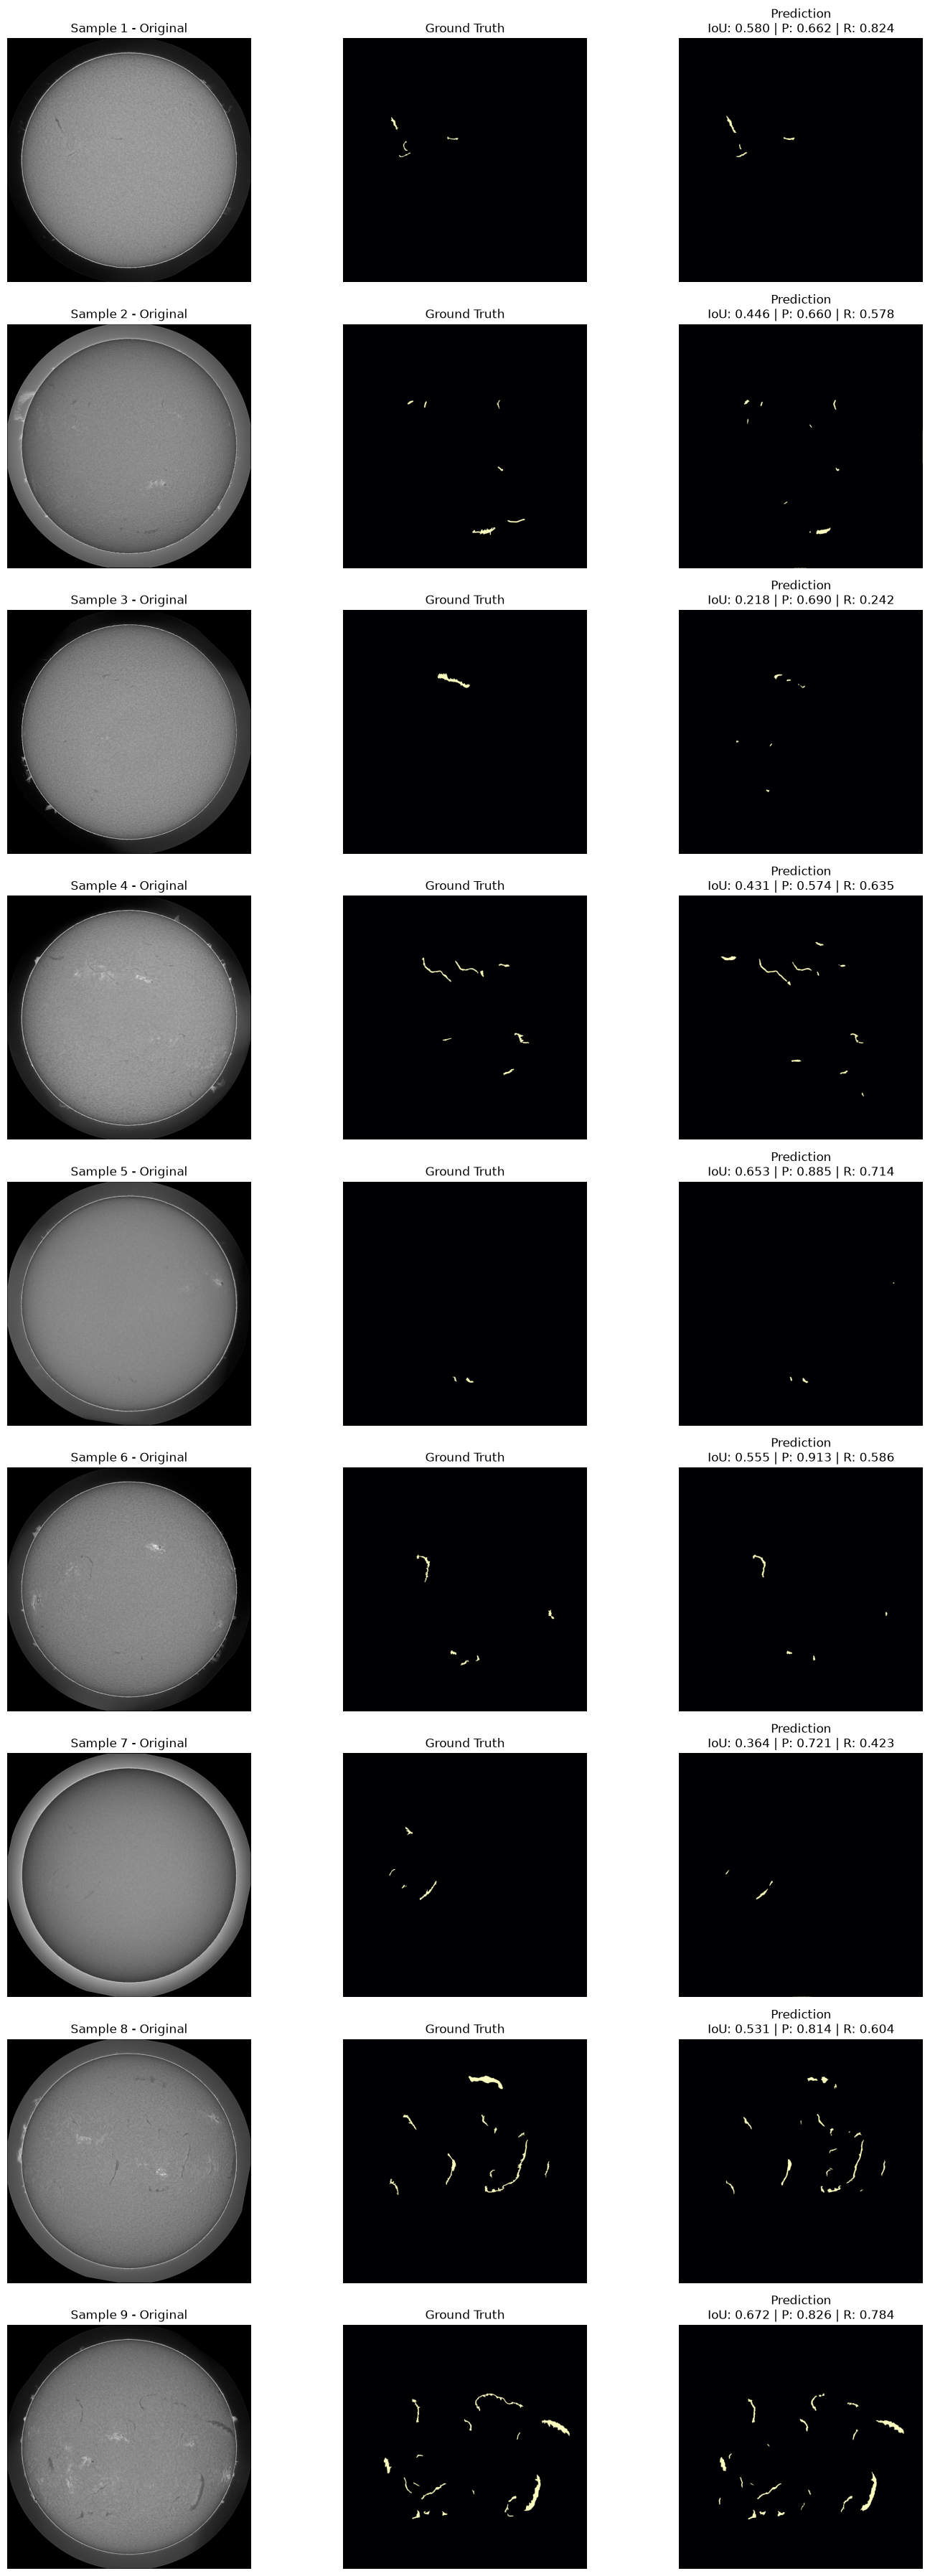

In [23]:
# Grab 9 samples from the full validation dataset and plot in a clean 9x3 grid
num_samples = 9
fig, axes = plt.subplots(num_samples, 3, figsize=(15, 4 * num_samples))

model.eval()
with torch.no_grad():
    for idx in range(num_samples):
        img_tensor, mask_tensor = full_val_dataset[idx]
        
        # Run inference
        img_gpu = img_tensor.unsqueeze(0).to(device)
        logits = model(img_gpu)
        preds = (torch.sigmoid(logits) > 0.5).squeeze().cpu().numpy()
        
        # Apply our fast OpenCV noise filter
        preds_clean = remove_small_objects(preds, min_size=64)
        
        mask_np = mask_tensor.squeeze().numpy()
        img_np = img_tensor.squeeze().numpy()
        
        # Calculate sample-specific metrics
        intersection = np.logical_and(preds_clean, mask_np).sum()
        union = np.logical_or(preds_clean, mask_np).sum()
        tp = intersection
        fp = (preds_clean > mask_np).sum()
        fn = (mask_np > preds_clean).sum()
        
        iou = intersection / (union + 1e-6)
        precision = tp / (tp + fp + 1e-6)
        recall = tp / (tp + fn + 1e-6)
        
        # Row layout: [Original Image, Ground Truth Mask, Prediction + Metrics]
        ax_img, ax_gt, ax_pred = axes[idx]
        
        ax_img.imshow(img_np, cmap='gray')
        ax_img.set_title(f"Sample {idx+1} - Original")
        ax_img.axis('off')
        
        ax_gt.imshow(mask_np, cmap='magma')
        ax_gt.set_title(f"Ground Truth")
        ax_gt.axis('off')
        
        ax_pred.imshow(preds_clean, cmap='magma')
        ax_pred.set_title(f"Prediction\nIoU: {iou:.3f} | P: {precision:.3f} | R: {recall:.3f}")
        ax_pred.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# # Pseudo-label generation: The MORDEN data-scaling trick[cite: 1]
# # ponytail: Using self-training pseudo-labels with a high confidence threshold (0.85) 
# # to capture missed thin barbs without manual annotation overhead.

# model.load_state_dict(torch.load("best_resnet_unet_final.pt"))
# model.eval()

# pseudo_masks_dir = Path("../data/raw/train/pseudo_masks")
# pseudo_masks_dir.mkdir(parents=True, exist_ok=True)

# added_count = 0
# with torch.no_grad():
#     for img_id in train_ids:
#         img_path = str(train_dir / image_dict[img_id])
#         image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        
#         img_tensor = torch.from_numpy(image).float().unsqueeze(0).unsqueeze(0).to(device) / 255.0
#         logits = model(img_tensor)
        
#         probs = torch.sigmoid(logits).squeeze().cpu().numpy()
#         preds = (probs > 0.85).astype(np.uint8)
        
#         preds_clean = remove_small_objects(preds, min_size=64)
        
#         if preds_clean.sum() > 0:
#             cv2.imwrite(str(pseudo_masks_dir / f"{img_id}.png"), preds_clean * 255)
#             added_count += 1

# print(f"Generated {added_count} high-confidence pseudo-masks for dataset expansion.")

Generated 918 high-confidence pseudo-masks for dataset expansion.


In [ ]:
# # Extended Dataset class to blend real annotations and pseudo-masks seamlessly ((NET NEGATIVE) for missed barbs) dropping this 
# class ExpandedFilamentDataset(Dataset):
#     def __init__(self, image_ids, img_dir, img_dict, ann_dict, pseudo_dir, size):
#         self.image_ids = image_ids
#         self.img_dir = img_dir
#         self.img_dict = img_dict
#         self.ann_dict = ann_dict
#         self.pseudo_dir = Path(pseudo_dir)
#         self.size = size
        
#     def __len__(self):
#         return len(self.image_ids)
        
#     def __getitem__(self, idx):
#         img_id = self.image_ids[idx]
#         img_path = str(self.img_dir / self.img_dict[img_id])
        
#         image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
#         mask = np.zeros_like(image, dtype=np.uint8)
        
#         # 1. Load real annotations
#         centers = []
#         for ann in self.ann_dict.get(img_id, []):
#             for poly in ann.get("segmentation", []):
#                 poly_pts = np.round(np.array(poly, dtype=np.float32).reshape(-1, 2)).astype(np.int32)
#                 cv2.fillPoly(mask, [poly_pts], 1)
#                 centers.append(poly_pts.mean(axis=0))
                
#         # 2. Blend pseudo-mask if it exists (catches missed barbs)
#         pseudo_path = self.pseudo_dir / f"{img_id}.png"
#         if pseudo_path.exists():
#             p_mask = cv2.imread(str(pseudo_path), cv2.IMREAD_GRAYSCALE)
#             if p_mask is not None:
#                 mask = np.logical_or(mask, p_mask > 0).astype(np.uint8)
#                 # optionally add pseudo mask centroids to biasing pool
#                 ys, xs = np.where(p_mask > 0)
#                 if len(ys) > 0:
#                     centers.append(np.array([xs.mean(), ys.mean()]))

#         h, w = image.shape
#         th, tw = self.size
        
#         if len(centers) > 0 and torch.rand(1).item() > 0.5:
#             cx, cy = centers[torch.randint(len(centers), (1,)).item()]
#             i = np.clip(int(cy) - th // 2, 0, h - th)
#             j = np.clip(int(cx) - tw // 2, 0, w - tw)
#         else:
#             i = torch.randint(0, h - th + 1, size=(1,)).item()
#             j = torch.randint(0, w - tw + 1, size=(1,)).item()
            
#         image = image[i:i+th, j:j+tw]
#         mask = mask[i:i+th, j:j+tw]
        
#         image = torch.from_numpy(image).float().unsqueeze(0) / 255.0
#         mask = torch.from_numpy(mask).float().unsqueeze(0)
        
#         return image, mask

# # Swap loader and run 3 quick fine-tuning epochs to absorb pseudo-labels
# train_dataset = ExpandedFilamentDataset(train_ids, train_dir, image_dict, ann_dict, pseudo_masks_dir, size=(512, 512))
# train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=2, pin_memory=True)

In [ ]:
# # Fine-tune the model on the expanded dataset (real annotations + 918 pseudo-masks)
# finetune_model_path = "best_resnet_unet_pseudolabel.pt"
# optimizer = AdamW(model.parameters(), lr=5e-5) # Very low LR to gently adapt to pseudo-labels without forgetting real features
# epochs_pseudo = 3
# best_iou = 0.4700 # Previous baseline to beat

# print("Starting Pseudo-Label Fine-Tuning...")

# for epoch in range(epochs_pseudo):
#     model.train()
#     train_loss = 0.0
    
#     pbar = tqdm(train_loader, desc=f"Pseudo-Train Epoch {epoch+1}/{epochs_pseudo}")
#     for images, masks in pbar:
#         images, masks = images.to(device), masks.to(device)
        
#         optimizer.zero_grad()
#         logits = model(images)
#         loss = criterion(logits, masks)
        
#         loss.backward()
#         optimizer.step()
        
#         train_loss += loss.item()
#         pbar.set_postfix(loss=f"{loss.item():.4f}")
        
#     model.eval()
#     val_iou = 0.0
#     with torch.no_grad():
#         for images, masks in val_loader:
#             images, masks = images.to(device), masks.to(device)
#             logits = model(images)
#             val_iou += calculate_iou(logits, masks)
            
#     val_iou_mean = val_iou / len(val_loader)
#     print(f"Epoch {epoch+1} | Val Crop IoU: {val_iou_mean:.4f}")
    
#     if val_iou_mean > best_iou:
#         best_iou = val_iou_mean
#         torch.save(model.state_dict(), finetune_model_path)
#         print(f"  -> New best IoU! Saved to {finetune_model_path}")

# # Load ultimate weights
# model.load_state_dict(torch.load(finetune_model_path if Path(finetune_model_path).exists() else "best_resnet_unet_final.pt"))
# print("Pseudo-label fine-tuning complete.")

Starting Pseudo-Label Fine-Tuning...


Pseudo-Train Epoch 1/3: 100%|██████████| 231/231 [00:49<00:00,  4.65it/s, loss=0.2683]


Epoch 1 | Val Crop IoU: 0.5457
  -> New best IoU! Saved to best_resnet_unet_pseudolabel.pt


Pseudo-Train Epoch 2/3: 100%|██████████| 231/231 [00:49<00:00,  4.64it/s, loss=0.2421]


Epoch 2 | Val Crop IoU: 0.5431


Pseudo-Train Epoch 3/3: 100%|██████████| 231/231 [00:49<00:00,  4.64it/s, loss=0.1523]


Epoch 3 | Val Crop IoU: 0.5460
  -> New best IoU! Saved to best_resnet_unet_pseudolabel.pt
Pseudo-label fine-tuning complete.


In [1]:

model.load_state_dict(torch.load("best_resnet_unet_final.pt"))

print("Locked in peak weights: 0.4700 IoU checkpoint ready for export.")

NameError: name 'model' is not defined

In [ ]:
import torch.nn.functional as F

print("Evaluating validation set artificially downscaled to 1024x1024...")

model.eval()
val_iou, val_precision, val_recall = 0.0, 0.0, 0.0

with torch.no_grad():
    pbar = tqdm(full_val_dataset, desc="1024x1024 Eval")
    for img_tensor, mask_tensor in pbar:
        # Move to GPU and add batch dimension
        img_gpu = img_tensor.unsqueeze(0).to(device)
        
        # 1. Downsample the input to 1024x1024
        img_1024 = F.interpolate(img_gpu, size=(1024, 1024), mode='bilinear', align_corners=False)
        
        # Run inference
        logits = model(img_1024)
        preds = (torch.sigmoid(logits) > 0.5).squeeze().cpu().numpy()
        
        # 2. Scale our noise filter threshold down by 4x to match the area reduction
        preds_clean = remove_small_objects(preds, min_size=16)
        
        # 3. Downsample the ground truth mask to 1024x1024 (nearest neighbor to keep it binary)
        mask_np = mask_tensor.squeeze().numpy()
        mask_1024 = cv2.resize(mask_np, (1024, 1024), interpolation=cv2.INTER_NEAREST)
        
        # Calculate metrics on the 1024x1024 grid
        intersection = np.logical_and(preds_clean, mask_1024).sum()
        union = np.logical_or(preds_clean, mask_1024).sum()
        
        tp = intersection
        fp = (preds_clean > mask_1024).sum()
        fn = (mask_1024 > preds_clean).sum()
        
        val_iou += intersection / (union + 1e-6)
        val_precision += tp / (tp + fp + 1e-6)
        val_recall += tp / (tp + fn + 1e-6)

n_val = len(full_val_dataset)
print(f"\n1024x1024 Vanity Metrics:")
print(f"Mean IoU:       {val_iou / n_val:.4f}")
print(f"Mean Precision: {val_precision / n_val:.4f}")
print(f"Mean Recall:    {val_recall / n_val:.4f}")

In [16]:
## independent sanity check

import json
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from pathlib import Path
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

# 1. Setup & Parsing (Recreating the exact validation split)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_dir = Path("../data/raw/train/train_images")
json_path = Path("../data/raw/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json")

with open(json_path, "r") as f:
    coco = json.load(f)

image_dict = {img["id"]: img["file_name"] for img in coco["images"]}
ann_dict = {}
for ann in coco["annotations"]:
    ann_dict.setdefault(ann["image_id"], []).append(ann)

image_ids = list(image_dict.keys())
counts = [len(ann_dict.get(i, [])) for i in image_ids]
bins = np.digitize(counts, bins=[3, 7, 12, 18]) 
_, val_ids = train_test_split(image_ids, test_size=0.2, stratify=bins, random_state=42)

# 2. Dataset Definition
class FullDiskDataset(Dataset):
    def __init__(self, image_ids, img_dir, img_dict, ann_dict):
        self.image_ids = image_ids
        self.img_dir = img_dir
        self.img_dict = img_dict
        self.ann_dict = ann_dict
        
    def __len__(self): return len(self.image_ids)
        
    def __getitem__(self, idx):
        img_id = self.image_ids[idx]
        img_path = str(self.img_dir / self.img_dict[img_id])
        
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask = np.zeros_like(image, dtype=np.uint8)
        
        for ann in self.ann_dict.get(img_id, []):
            for poly in ann.get("segmentation", []):
                poly_pts = np.round(np.array(poly, dtype=np.float32).reshape(-1, 2)).astype(np.int32)
                cv2.fillPoly(mask, [poly_pts], 1)
                
        image = torch.from_numpy(image).float().unsqueeze(0) / 255.0
        mask = torch.from_numpy(mask).float().unsqueeze(0)
        return image, mask

full_val_dataset = FullDiskDataset(val_ids, train_dir, image_dict, ann_dict)

# 3. Model Architecture
class ResNetUNet(nn.Module):
    def __init__(self):
        super().__init__()
        resnet = models.resnet34(weights=None) # Weights=None since we are loading our own state_dict
        
        self.firstconv = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.firstbn = resnet.bn1
        self.firstrelu = resnet.relu
        self.firstmaxpool = resnet.maxpool
        
        self.encoder1 = resnet.layer1
        self.encoder2 = resnet.layer2
        self.encoder3 = resnet.layer3
        self.encoder4 = resnet.layer4
        
        def dec_block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, padding=1), nn.InstanceNorm2d(out_c), nn.LeakyReLU(0.01, inplace=True),
                nn.Conv2d(out_c, out_c, 3, padding=1), nn.InstanceNorm2d(out_c), nn.LeakyReLU(0.01, inplace=True)
            )
            
        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = dec_block(512, 256) 
        
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = dec_block(256, 128) 
        
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = dec_block(128, 64)  
        
        self.up1 = nn.ConvTranspose2d(64, 64, 2, stride=2)
        self.dec1 = dec_block(128, 64)  
        
        self.final_up = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.final_dec = dec_block(32, 16)
        
        self.out = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        e0 = self.firstrelu(self.firstbn(self.firstconv(x)))
        e1 = self.encoder1(self.firstmaxpool(e0))
        e2 = self.encoder2(e1)
        e3 = self.encoder3(e2)
        b = self.encoder4(e3)
        
        d4 = self.dec4(torch.cat([self.up4(b), e3], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e2], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e1], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e0], 1))
        return self.out(self.final_dec(self.final_up(d1)))

# 4. Load Weights
model = ResNetUNet().to(device)
model.load_state_dict(torch.load("best_resnet_unet_final.pt", map_location=device))
model.eval()
print("Peak weights loaded successfully.")

# 5. Post-Processing & 1024x1024 Evaluation
def remove_small_objects(binary_mask, min_size=16):
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary_mask.astype(np.uint8), connectivity=8)
    clean_mask = np.zeros_like(binary_mask)
    for i in range(1, num_labels):
        if stats[i, cv2.CC_STAT_AREA] >= min_size:
            clean_mask[labels == i] = 1
    return clean_mask

print("Evaluating validation set artificially downscaled to 1024x1024...")

val_iou, val_precision, val_recall = 0.0, 0.0, 0.0

with torch.no_grad():
    pbar = tqdm(full_val_dataset, desc="1024x1024 Eval")
    for img_tensor, mask_tensor in pbar:
        img_gpu = img_tensor.unsqueeze(0).to(device)
        
        img_1024 = F.interpolate(img_gpu, size=(1024, 1024), mode='bilinear', align_corners=False)
        
        logits = model(img_1024)
        preds = (torch.sigmoid(logits) > 0.5).squeeze().cpu().numpy()
        
        preds_clean = remove_small_objects(preds, min_size=16)
        
        mask_np = mask_tensor.squeeze().numpy()
        mask_1024 = cv2.resize(mask_np, (1024, 1024), interpolation=cv2.INTER_NEAREST)
        
        intersection = np.logical_and(preds_clean, mask_1024).sum()
        union = np.logical_or(preds_clean, mask_1024).sum()
        
        tp = intersection
        fp = (preds_clean > mask_1024).sum()
        fn = (mask_1024 > preds_clean).sum()
        
        val_iou += intersection / (union + 1e-6)
        val_precision += tp / (tp + fp + 1e-6)
        val_recall += tp / (tp + fn + 1e-6)

n_val = len(full_val_dataset)
print(f"\n1024x1024 Vanity Metrics:")
print(f"Mean IoU:       {val_iou / n_val:.4f}")
print(f"Mean Precision: {val_precision / n_val:.4f}")
print(f"Mean Recall:    {val_recall / n_val:.4f}")

Peak weights loaded successfully.
Evaluating validation set artificially downscaled to 1024x1024...


1024x1024 Eval: 100%|██████████| 231/231 [00:19<00:00, 11.70it/s]


1024x1024 Vanity Metrics:
Mean IoU:       0.3523
Mean Precision: 0.6382
Mean Recall:    0.4456


In [1]:
# ponytail: Test-Time Augmentation (TTA). 
# Trades 3x inference time for free recall and boundary smoothing without new dependencies.

print("Evaluating full validation set (2048x2048) with TTA...")

model.eval()
val_iou, val_precision, val_recall = 0.0, 0.0, 0.0

with torch.no_grad():
    pbar = tqdm(full_val_dataset, desc="Full-Disk TTA Eval")
    for img_tensor, mask_tensor in pbar:
        img_gpu = img_tensor.unsqueeze(0).to(device)
        mask_np = mask_tensor.squeeze().numpy()
        
        # 1. Forward passes across three orientations (dim 2=H, dim 3=W)
        with torch.amp.autocast('cuda'):
            logits_base = model(img_gpu)
            logits_h = torch.flip(model(torch.flip(img_gpu, dims=[3])), dims=[3])
            logits_v = torch.flip(model(torch.flip(img_gpu, dims=[2])), dims=[2])
        
        # 2. Average probabilities before thresholding
        probs = (torch.sigmoid(logits_base) + torch.sigmoid(logits_h) + torch.sigmoid(logits_v)) / 3.0
        preds = (probs > 0.5).squeeze().cpu().numpy()
        
        # 3. Fast area filter to remove speckle noise
        preds_clean = remove_small_objects(preds, min_size=64)
        
        # 4. Metric calculation
        intersection = np.logical_and(preds_clean, mask_np).sum()
        union = np.logical_or(preds_clean, mask_np).sum()
        
        tp = intersection
        fp = (preds_clean > mask_np).sum()
        fn = (mask_np > preds_clean).sum()
        
        val_iou += intersection / (union + 1e-6)
        val_precision += tp / (tp + fp + 1e-6)
        val_recall += tp / (tp + fn + 1e-6)

n_val = len(full_val_dataset)
print(f"\nFinal TTA Metrics:")
print(f"Mean IoU:       {val_iou / n_val:.4f}")
print(f"Mean Precision: {val_precision / n_val:.4f}")
print(f"Mean Recall:    {val_recall / n_val:.4f}")

Evaluating full validation set (2048x2048) with TTA...


NameError: name 'model' is not defined